# BDB 2027 — OL Usage, Load & Injury Risk: descriptive deep dive

**Goal:** lay out every angle in this dataset that could feed a model of **usage** (how much an OL plays) or **injury risk** (proxied by absences and in-game exits), using three input families:

| Input family | Source | Examples |
|---|---|---|
| Measurements | `combine_results` | height, weight, BMI, arm length, weight vs. position norm |
| Combine athleticism & behavior | `combine_results` | 10-yd split, broad/vertical, 3-cone, shuttle, bench, composite indices, **opt-outs** |
| Combine movement quality | `combine_tracking` | peak braking, lateral speed, **left/right asymmetry** in lateral drills |
| In-game workload | `player_play` + `game_tracking` | snaps, post-snap distance, high-intensity accel/decel, **acute:chronic load ratio** |
| Context | `games` | days of rest, surface (if present), week of season |

**Everything here is descriptive.** Rates come with Poisson or bootstrap intervals, and nothing is a fitted predictive model yet. Section 11 maps each angle to the modeling approach it would support.

### Outcome definitions (no injury table exists, so these are proxies)
- **Usage rate**: games played ÷ team games, and snaps per team game.
- **Absence episode**: he played team game *g−1* (as an established regular), then logged 0 snaps in game *g* while staying on the same team. The episode's length in games is tracked. A **long absence** is ≥ `LONG_ABSENCE` games, which is IR-like.
- **In-game exit**: as an established regular, he played less than `EXIT_FRAC` of his trailing median snaps. **Exit → miss** (an exit followed by an absence episode the next game) is the strongest injury proxy here.
- Absences that end with the player showing up on a **different team** are treated as roster moves, not injuries.

These proxies can't separate injury from benching, healthy scratches or illness. Where possible, validate them against public injury reports (e.g. nflverse `injuries`) before using them as labels.

## 0. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 120); pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid", context="notebook")

CANDIDATES = [Path("data"), Path("../data"), Path("data/raw"), Path("/kaggle/input/nfl-big-data-bowl-2027")]
DATA_DIR = next((p for p in CANDIDATES if (p / "games.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("games.csv not found in: " + ", ".join(str(p.resolve()) for p in CANDIDATES))
print("Data dir:", DATA_DIR.resolve())
NULLS = ["NA", "NULL", "null", "None", ""]

def find_csv(stem):
    f = DATA_DIR / f"{stem}.csv"
    if not f.exists(): raise FileNotFoundError(f"{stem}.csv not found under {DATA_DIR.resolve()}")
    return f

def pick(df, candidates, required=False):
    lower = {c.lower(): c for c in df.columns}
    for c in candidates:
        if c.lower() in lower: return lower[c.lower()]
    if required: raise KeyError(f"None of {candidates} in {list(df.columns)}")
    return None

# ---- knobs ---------------------------------------------------------------
SEASONS       = [2023, 2024, 2025]
REGULAR_SNAPS = 30     # a game with ≥ this many snaps makes him an established regular
EXIT_FRAC     = 0.5    # in-game exit: snaps < 50% of his trailing median
LONG_ABSENCE  = 4      # absence spells this long or longer = "long" (IR-like)
LOAD_WINDOW_S = 4.0    # seconds after the snap counted toward per-rep load
HI_ACCEL      = 3.0    # yd/s² threshold for a high-intensity accel/decel frame
N_BOOT        = 2000
RNG           = np.random.default_rng(27)
TRK_CACHE     = Path("ol_tracking_cache.parquet")   # shared with the movement-classes notebook
# --------------------------------------------------------------------------

def poisson_ci(events, exposure, per=100, alpha=0.05):
    lo = stats.chi2.ppf(alpha / 2, 2 * events) / 2 if events > 0 else 0.0
    hi = stats.chi2.ppf(1 - alpha / 2, 2 * (events + 1)) / 2
    return per * events / exposure, per * lo / exposure, per * hi / exposure

def rate_table(df, by, events, exposure, per=100):
    # Event rate per `per` exposure units with exact Poisson 95% CI, by group
    g = df.groupby(by, observed=True).agg(players=("nfl_id", "nunique"), events=(events, "sum"), exposure=(exposure, "sum"))
    ci = [poisson_ci(e, x, per) if x > 0 else (np.nan,) * 3 for e, x in zip(g["events"], g["exposure"])]
    g[["rate", "ci_lo", "ci_hi"]] = pd.DataFrame(ci, index=g.index, columns=["rate", "ci_lo", "ci_hi"]) if ci else np.nan
    return g.round(2)

def boot_spearman(x, y, n=N_BOOT):
    m = pd.notna(x) & pd.notna(y); x, y = np.asarray(x[m]), np.asarray(y[m])
    if len(x) < 10: return np.nan, np.nan, np.nan, len(x)
    r = stats.spearmanr(x, y)[0]
    idx = RNG.integers(0, len(x), (n, len(x)))
    bs = [stats.spearmanr(x[i], y[i])[0] for i in idx]
    return r, *np.nanpercentile(bs, [2.5, 97.5]), len(x)

def plot_rates(tab, title, ax=None, xlabel="rate per 100 team games"):
    ax = ax or plt.subplots(figsize=(7, 0.45 * len(tab) + 1.2))[1]
    y = np.arange(len(tab))
    ax.errorbar(tab["rate"], y, xerr=[tab["rate"] - tab["ci_lo"], tab["ci_hi"] - tab["rate"]], fmt="o", color="#4C72B0")
    ax.set_yticks(y); ax.set_yticklabels([f"{i}  (events={int(e)})" for i, e in zip(tab.index.astype(str), tab["events"])])
    ax.set_xlabel(xlabel); ax.set_title(title); ax.invert_yaxis()
    return ax

Data dir: C:\Users\bchm5\TSLR\USC-NFL-Big-Data-Bowl-2027\data


## 1. Load and build the OL roster

In [2]:
players = pd.read_csv(find_csv("players"), na_values=NULLS)
combine = pd.read_csv(find_csv("combine_results"), na_values=NULLS)
career  = pd.read_csv(find_csv("player_career_successes"), na_values=NULLS)
games   = pd.read_csv(find_csv("games"), na_values=NULLS)
pp      = pd.read_csv(find_csv("player_play"), na_values=NULLS, low_memory=False)

prof = (players.merge(combine.drop(columns=[c for c in combine if c in players and c != "nfl_id"]), on="nfl_id", how="left")
               .merge(career.drop(columns=[c for c in career if c in players and c != "nfl_id"]), on="nfl_id", how="left"))
NAME = pick(prof, ["display_name", "player_name", "full_name", "name"])
NFL_POS, CMB_POS = pick(prof, ["nfl_position", "position"]), pick(prof, ["combine_position"])
DRAFT_YR = pick(prof, ["draft_year"], required=True)
ROUND = pick(prof, ["draft_round"]); PICK = pick(prof, ["draft_pick", "draft_overall_pick", "overall_pick", "draft_number"])
BDAY  = pick(prof, ["birth_date", "birthdate", "dob"])
LUP   = pick(pp, ["lined_up_position", "position_at_snap"], required=True)
TEAM  = pick(pp, ["team_abbr", "club", "team"], required=True)
GDATE = pick(games, ["game_date", "date", "gameday"])
SURF  = pick(games, ["surface", "playing_surface", "field_surface", "turf"])
HOME, AWAY = pick(games, ["home_team_abbr"]), pick(games, ["visitor_team_abbr", "away_team_abbr"])
print(dict(NAME=NAME, NFL_POS=NFL_POS, CMB_POS=CMB_POS, ROUND=ROUND, PICK=PICK, BDAY=BDAY, GDATE=GDATE, SURF=SURF))

def to_group(p):
    if pd.isna(p): return np.nan
    p = str(p).upper().strip()
    if p in {"C", "OC"}: return "C"
    if p in {"G", "OG", "LG", "RG"}: return "G"
    if p in {"T", "OT", "LT", "RT"}: return "T"
    return np.nan

OL_LABELS = {"OL", "OT", "OG", "IOL", "C", "G", "T", "LT", "RT", "LG", "RG", "OC"}
is_ol = pd.Series(False, index=prof.index)
for c in [CMB_POS, NFL_POS]:
    if c: is_ol |= prof[c].astype(str).str.upper().isin(OL_LABELS)
ol = prof[is_ol].copy()
ol["listed_group"] = ol[NFL_POS].map(to_group) if NFL_POS else np.nan
if CMB_POS: ol["listed_group"] = ol["listed_group"].fillna(ol[CMB_POS].map(to_group))

gcols = ["game_id", "season", "week"] + [c for c in ["season_type", GDATE, SURF, HOME, AWAY] if c]
ol_pp = pp[pp["nfl_id"].isin(ol["nfl_id"])].merge(games[gcols], on="game_id", how="left")
if "season_type" in ol_pp: ol_pp = ol_pp[ol_pp["season_type"].fillna("REG") == "REG"]
ol_pp["lup_group"] = ol_pp[LUP].map(to_group)
share = ol_pp.dropna(subset=["lup_group"]).groupby(["nfl_id", "lup_group"]).size().unstack(fill_value=0)
for g in "CGT":
    if g not in share: share[g] = 0
ol = ol.merge(share[list("CGT")].sum(axis=1).rename("ol_snaps").to_frame().join(share[list("CGT")].idxmax(axis=1).rename("played_group")),
              left_on="nfl_id", right_index=True, how="left")
ol["pos_group"] = np.where(ol["ol_snaps"].fillna(0) >= 50, ol["played_group"], ol["listed_group"])
ol["is_udfa"] = ol[ROUND].isna() if ROUND else np.nan
if BDAY:
    ol["age_at_draft"] = (pd.to_datetime(ol[DRAFT_YR].astype(int).astype(str) + "-04-25")
                          - pd.to_datetime(ol[BDAY], errors="coerce")).dt.days / 365.25
print(f"{len(ol)} OL | pos_group:", ol["pos_group"].value_counts(dropna=False).to_dict())

{'NAME': 'display_name', 'NFL_POS': 'nfl_position', 'CMB_POS': 'combine_position', 'ROUND': 'draft_round', 'PICK': 'draft_overall_pick', 'BDAY': 'birth_date', 'GDATE': None, 'SURF': None}
121 OL | pos_group: {'G': 53, 'T': 49, 'C': 19}


## 2. Player-game panel and outcome events

Each player-season is expanded to his team's full regular-season schedule, with a row for every team game. A mid-season team change splits the season into separate stints, so a release or trade doesn't look like an absence.

In [3]:
sched = pd.concat([games[["game_id", "season", "week", HOME]].rename(columns={HOME: "team"}).assign(home=1),
                   games[["game_id", "season", "week", AWAY]].rename(columns={AWAY: "team"}).assign(home=0)])
extra = [c for c in [GDATE, SURF] if c]
if extra: sched = sched.merge(games[["game_id"] + extra], on="game_id", how="left")
if "season_type" in games:
    sched = sched[sched["game_id"].isin(games.loc[games["season_type"] == "REG", "game_id"])]
if GDATE:
    sched["gdate"] = pd.to_datetime(sched[GDATE], errors="coerce")
    sched = sched.sort_values(["team", "gdate"])
    sched["rest_days"] = sched.groupby(["team", "season"])["gdate"].diff().dt.days
else:
    sched = sched.sort_values(["team", "season", "week"])
    sched["rest_days"] = np.nan
sched["team_game_no"] = sched.groupby(["team", "season"]).cumcount() + 1

pg = (ol_pp.groupby(["nfl_id", "game_id", "season", "week"])
           .agg(snaps=("play_id", "size"), team=(TEAM, "first")).reset_index())

# Stints: contiguous (player, season, team) spans from first to last game he played for that team
stint = (pg.merge(sched[["game_id", "team", "team_game_no"]], on=["game_id", "team"])
           .groupby(["nfl_id", "season", "team"])["team_game_no"].agg(first_g="min", last_g="max").reset_index())
moved_later = stint.groupby(["nfl_id", "season"])["team"].transform("nunique") > 1
stint["multi_team_season"] = moved_later

panel = stint.merge(sched, on=["season", "team"])
# Keep games from his first appearance onward; after his last appearance, keep only if he never moved teams
panel = panel[(panel["team_game_no"] >= panel["first_g"]) &
              ((panel["team_game_no"] <= panel["last_g"]) | ~panel["multi_team_season"])]
panel = panel.merge(pg[["nfl_id", "game_id", "snaps"]], on=["nfl_id", "game_id"], how="left")
panel["snaps"] = panel["snaps"].fillna(0)
panel = panel.sort_values(["nfl_id", "season", "team", "team_game_no"]).reset_index(drop=True)
grp = panel.groupby(["nfl_id", "season", "team"])

panel["played"] = panel["snaps"] > 0
panel["established"] = grp["snaps"].transform(lambda s: (s >= REGULAR_SNAPS).shift(fill_value=False).cummax())
panel["prev_played"] = grp["played"].shift(fill_value=False)
panel["trail_med"] = grp["snaps"].transform(lambda s: s.where(s >= REGULAR_SNAPS).shift().expanding().median())

# Absence episode start + its length
panel["absence_start"] = panel["established"] & panel["prev_played"] & ~panel["played"]
panel["spell_id"] = (panel["played"] != grp["played"].shift()).cumsum()
spell_len = panel[~panel["played"]].groupby("spell_id").size()
panel["spell_len"] = panel["spell_id"].map(spell_len).where(panel["absence_start"])
panel["long_absence_start"] = panel["absence_start"] & (panel["spell_len"] >= LONG_ABSENCE)

# In-game exit and exit → miss
panel["exit"] = panel["established"] & panel["played"] & panel["trail_med"].notna() & \
                (panel["snaps"] < EXIT_FRAC * panel["trail_med"])
panel["exit_then_miss"] = panel["exit"] & grp["absence_start"].shift(-1, fill_value=False)
panel["at_risk"] = panel["established"] & panel["prev_played"]   # exposure for absence starts

print(f"Panel: {len(panel):,} player-team-games | players: {panel['nfl_id'].nunique()}")
print({k: int(panel[k].sum()) for k in ["absence_start", "long_absence_start", "exit", "exit_then_miss", "at_risk"]})

Panel: 2,277 player-team-games | players: 91
{'absence_start': 135, 'long_absence_start': 38, 'exit': 133, 'exit_then_miss': 52, 'at_risk': 1379}


In [4]:
# Player-level outcomes
P = panel.groupby("nfl_id").agg(
    team_games=("game_id", "size"), games_played=("played", "sum"), snaps=("snaps", "sum"),
    at_risk=("at_risk", "sum"), absence_starts=("absence_start", "sum"),
    long_absences=("long_absence_start", "sum"), exits=("exit", "sum"),
    exit_then_miss=("exit_then_miss", "sum"), seasons=("season", "nunique"))
P["usage_rate"] = P["games_played"] / P["team_games"]
P["snaps_per_team_game"] = P["snaps"] / P["team_games"]
P["any_long_absence"] = P["long_absences"] > 0
ol = ol.drop(columns=[c for c in P if c in ol]).merge(P, left_on="nfl_id", right_index=True, how="left")
ol["in_panel"] = ol["team_games"].fillna(0) > 0
ol["seasons_available"] = max(SEASONS) - ol[DRAFT_YR] + 1
ol["cohort_retained"] = ol["seasons"].fillna(0) / ol["seasons_available"]
print(f"OL with any NFL games: {ol['in_panel'].sum()} of {len(ol)}")

OL with any NFL games: 91 of 121


## 3. Outcome overview: how much signal is there to work with?

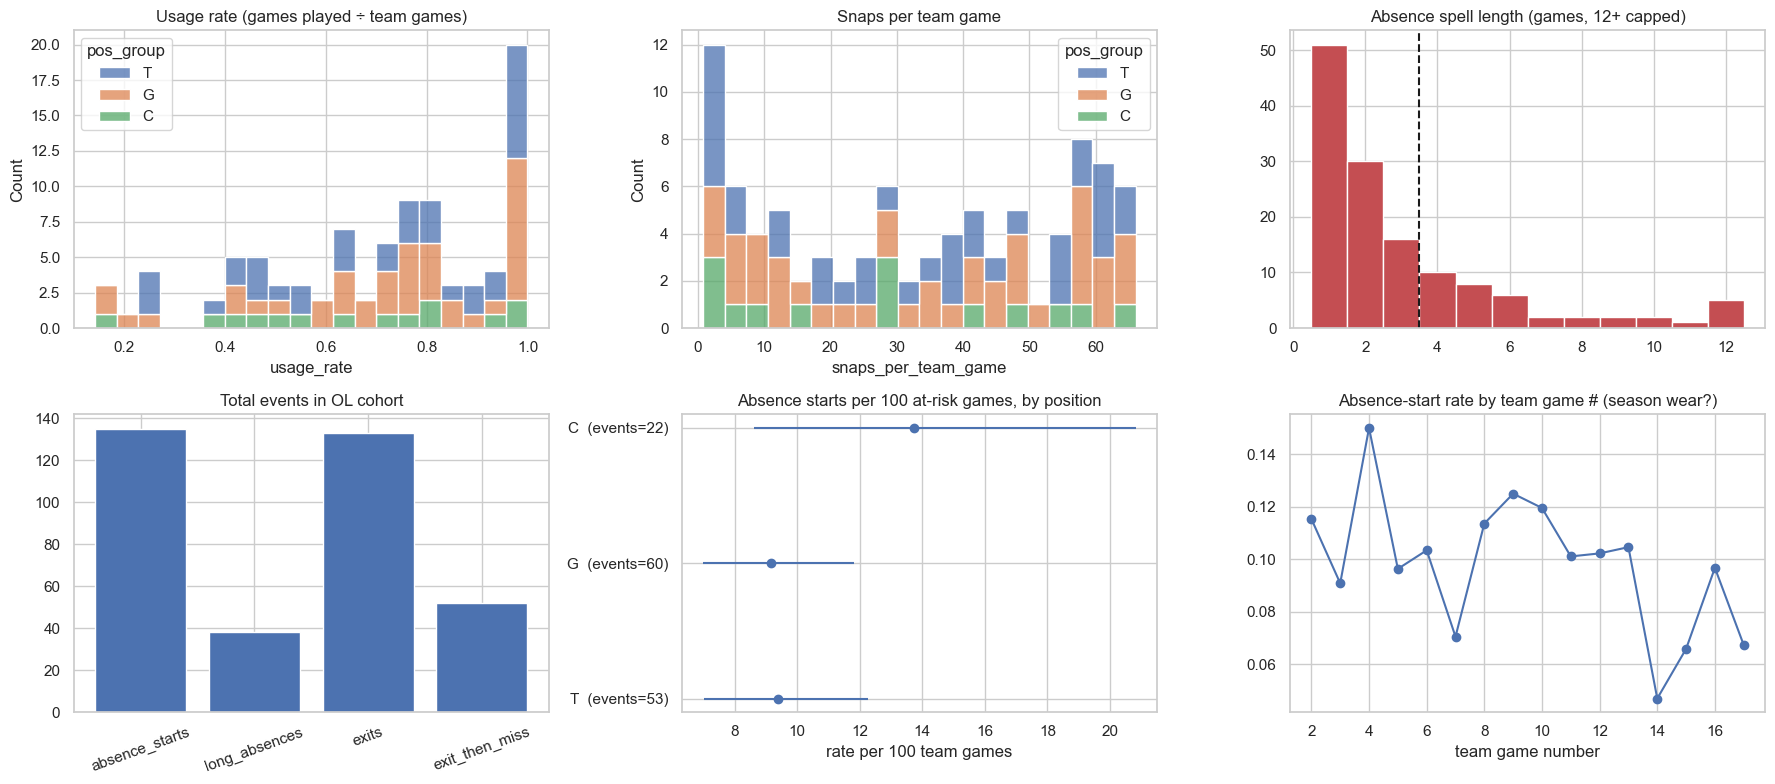

,players,events,exposure,rate,ci_lo,ci_hi
pos_group,,,,,,
C,14,22,160,13.75,8.62,20.82
G,41,60,654,9.17,7.00,11.81
T,36,53,565,9.38,7.03,12.27


In [5]:
o = ol[ol["in_panel"]]
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
sns.histplot(o, x="usage_rate", hue="pos_group", multiple="stack", bins=20, ax=axes[0, 0]); axes[0, 0].set_title("Usage rate (games played ÷ team games)")
sns.histplot(o, x="snaps_per_team_game", hue="pos_group", multiple="stack", bins=20, ax=axes[0, 1]); axes[0, 1].set_title("Snaps per team game")
spells = panel.loc[panel["absence_start"], "spell_len"]
axes[0, 2].hist(spells.clip(upper=12), bins=np.arange(1, 14) - .5, color="#C44E52")
axes[0, 2].axvline(LONG_ABSENCE - .5, color="k", ls="--"); axes[0, 2].set_title("Absence spell length (games, 12+ capped)")
ev = o[["absence_starts", "long_absences", "exits", "exit_then_miss"]].sum()
axes[1, 0].bar(ev.index, ev.values, color="#4C72B0"); axes[1, 0].set_title("Total events in OL cohort"); axes[1, 0].tick_params(axis="x", rotation=20)
tab = rate_table(panel.merge(ol[["nfl_id", "pos_group"]], on="nfl_id").assign(one=1), "pos_group", "absence_start", "at_risk")
plot_rates(tab, "Absence starts per 100 at-risk games, by position", ax=axes[1, 1])
wk = panel[panel["at_risk"]].groupby("team_game_no")["absence_start"].mean()
axes[1, 2].plot(wk.index, wk.values, "o-"); axes[1, 2].set_title("Absence-start rate by team game # (season wear?)")
axes[1, 2].set_xlabel("team game number")
plt.tight_layout(); plt.show()
display(tab)

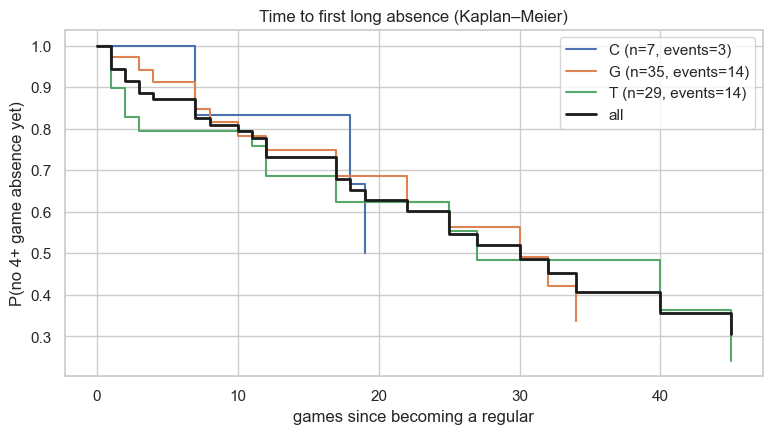

In [6]:
# Kaplan–Meier: games from first established game until first LONG absence (IR-like), by position
def km(durations, events):
    d = pd.DataFrame({"t": durations, "e": events}).dropna().sort_values("t")
    times = np.sort(d.loc[d["e"] == 1, "t"].unique())
    S, out, n = 1.0, [(0, 1.0)], len(d)
    for t in times:
        at_risk = (d["t"] >= t).sum(); died = ((d["t"] == t) & (d["e"] == 1)).sum()
        S *= 1 - died / at_risk; out.append((t, S))
    return pd.DataFrame(out, columns=["t", "S"])

est = panel[panel["established"]].copy()
est["g_since_est"] = est.groupby("nfl_id").cumcount() + 1
first_long = est[est["long_absence_start"]].groupby("nfl_id")["g_since_est"].min()
followed = est.groupby("nfl_id")["g_since_est"].max()
surv = pd.DataFrame({"t": followed}).join(first_long.rename("t_event"))
surv["event"] = surv["t_event"].notna().astype(int)
surv["t"] = surv["t_event"].fillna(surv["t"])
surv = surv.join(ol.set_index("nfl_id")[["pos_group"]])

fig, ax = plt.subplots(figsize=(9, 4.5))
for g, d in surv.groupby("pos_group"):
    k = km(d["t"], d["event"]); ax.step(k["t"], k["S"], where="post", label=f"{g} (n={len(d)}, events={d['event'].sum()})")
k = km(surv["t"], surv["event"]); ax.step(k["t"], k["S"], where="post", color="k", lw=2, label="all")
ax.set_xlabel("games since becoming a regular"); ax.set_ylabel(f"P(no {LONG_ABSENCE}+ game absence yet)")
ax.set_title("Time to first long absence (Kaplan–Meier)"); ax.legend(); plt.show()

## 4. Angle 1: Body measurements

Size is the obvious first suspect for linemen. More mass means more joint load per step, and bigger players also get more snaps because coaches want them in the lineup. Weight is shown both raw and **relative to the position norm**, so a 330-lb tackle isn't treated like a 330-lb center.

Each panel shows event rates by tercile with exact Poisson CIs, plus usage by tercile.

Body measures: ['combine_height', 'combine_weight', 'bmi', 'combine_weight_vs_pos', 'bmi_vs_pos', 'arm_length', 'hand_size']


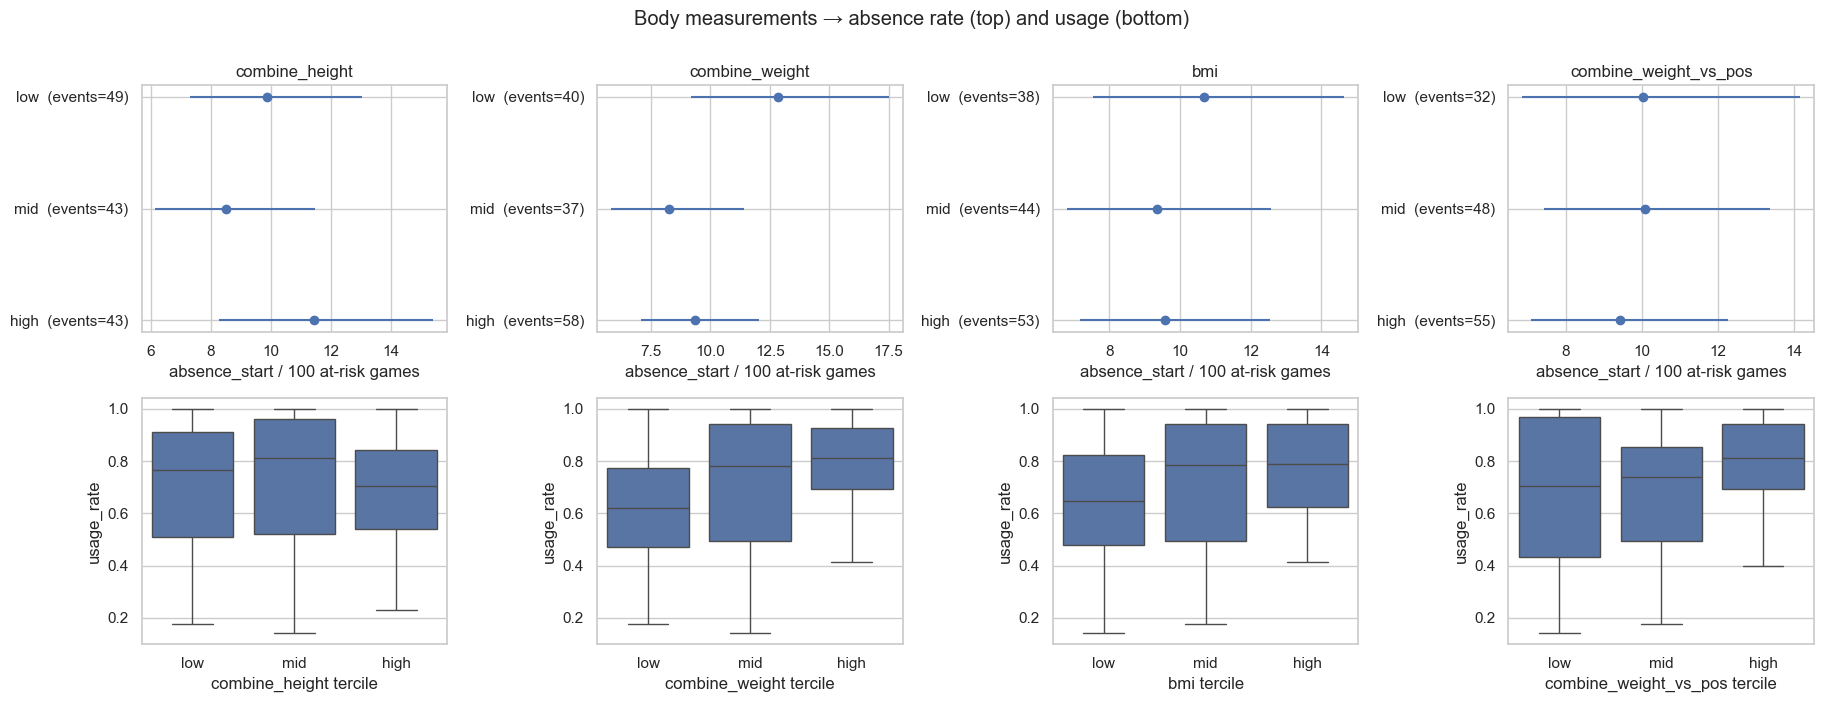

,metric,rate_low,rate_high,rate_ratio_high_vs_low,events,usage_spearman,usage_ci,n
0,combine_height,9.86,11.44,1.160,135,0.004,"[-0.19, 0.19]",91
1,combine_weight,12.86,9.34,0.726,135,0.237,"[0.05, 0.40]",91
2,bmi,10.67,9.58,0.898,135,0.175,"[-0.01, 0.36]",91
3,combine_weight_vs_pos,10.03,9.42,0.939,135,0.188,"[-0.01, 0.37]",91
4,bmi_vs_pos,11.89,8.32,0.700,135,0.177,"[-0.03, 0.36]",91
5,arm_length,12.16,12.04,0.990,135,0.084,"[-0.12, 0.28]",91
6,hand_size,8.32,10.00,1.202,135,0.042,"[-0.15, 0.23]",91


In [7]:
H, W = pick(ol, ["combine_height", "height"]), pick(ol, ["combine_weight", "weight"])
ARM, HAND, WING = pick(ol, ["arm_length", "arms"]), pick(ol, ["hand_size", "hands"]), pick(ol, ["wingspan"])
if H and W: ol["bmi"] = 703 * ol[W] / ol[H] ** 2
for c in [W, "bmi"]:
    if c: ol[f"{c}_vs_pos"] = ol[c] - ol.groupby("pos_group")[c].transform("median")
BODY = [c for c in [H, W, "bmi", f"{W}_vs_pos" if W else None, "bmi_vs_pos", ARM, HAND, WING] if c and c in ol]
print("Body measures:", BODY)

def tercile_view(cols, outcome="absence_start", exposure="at_risk", title=""):
    cols = [c for c in cols if ol.loc[ol["in_panel"], c].notna().sum() >= 15]
    if not cols: print("not enough data"); return pd.DataFrame()
    pan = panel.merge(ol[["nfl_id"] + cols], on="nfl_id")
    rows, ncols = [], min(4, len(cols))
    fig, axes = plt.subplots(2, ncols, figsize=(4.6 * ncols, 7), squeeze=False)
    for j, c in enumerate(cols):
        try: ol[f"_{c}_t"] = pd.qcut(ol[c], 3, labels=["low", "mid", "high"])
        except ValueError: continue
        pan[f"_{c}_t"] = pan["nfl_id"].map(ol.set_index("nfl_id")[f"_{c}_t"])
        t = rate_table(pan.dropna(subset=[f"_{c}_t"]), f"_{c}_t", outcome, exposure)
        if j < ncols:
            plot_rates(t, c, ax=axes[0, j], xlabel=f"{outcome} / 100 at-risk games")
            sns.boxplot(data=ol[ol["in_panel"]], x=f"_{c}_t", y="usage_rate", ax=axes[1, j], order=["low", "mid", "high"])
            axes[1, j].set_xlabel(f"{c} tercile")
        hi, lo = t.loc["high"] if "high" in t.index else None, t.loc["low"] if "low" in t.index else None
        r, rlo, rhi, n = boot_spearman(ol.loc[ol["in_panel"], c], ol.loc[ol["in_panel"], "usage_rate"])
        rows.append({"metric": c, "rate_low": lo["rate"] if lo is not None else np.nan,
                     "rate_high": hi["rate"] if hi is not None else np.nan,
                     "rate_ratio_high_vs_low": (hi["rate"] / lo["rate"]) if lo is not None and lo["rate"] > 0 else np.nan,
                     "events": int(t["events"].sum()), "usage_spearman": r, "usage_ci": f"[{rlo:.2f}, {rhi:.2f}]", "n": n})
    fig.suptitle(title, y=1.0); plt.tight_layout(); plt.show()
    ol.drop(columns=[c for c in ol if c.startswith("_") and c.endswith("_t")], inplace=True)
    return pd.DataFrame(rows).round(3)

res_body = tercile_view(BODY, title="Body measurements → absence rate (top) and usage (bottom)")
res_body

## 5. Angle 2: Combine athleticism (composite indices)

Single drills are noisy, so they're combined into position-adjusted composites. Each component is z-scored within C/G/T and signed so that **higher = better**:
- **Explosiveness**: broad jump, vertical, −10-yd split
- **Agility / change of direction**: −3-cone, −short shuttle
- **Strength**: bench reps
- **Speed score**: weight × 200 ÷ 40-time⁴. This is the classic size-adjusted speed metric.

The athletic-reserve hypothesis says more explosive and agile linemen handle load better. The counter-hypothesis says explosive athletes generate higher peak forces. Either way, the tercile view shows which direction the data leans.

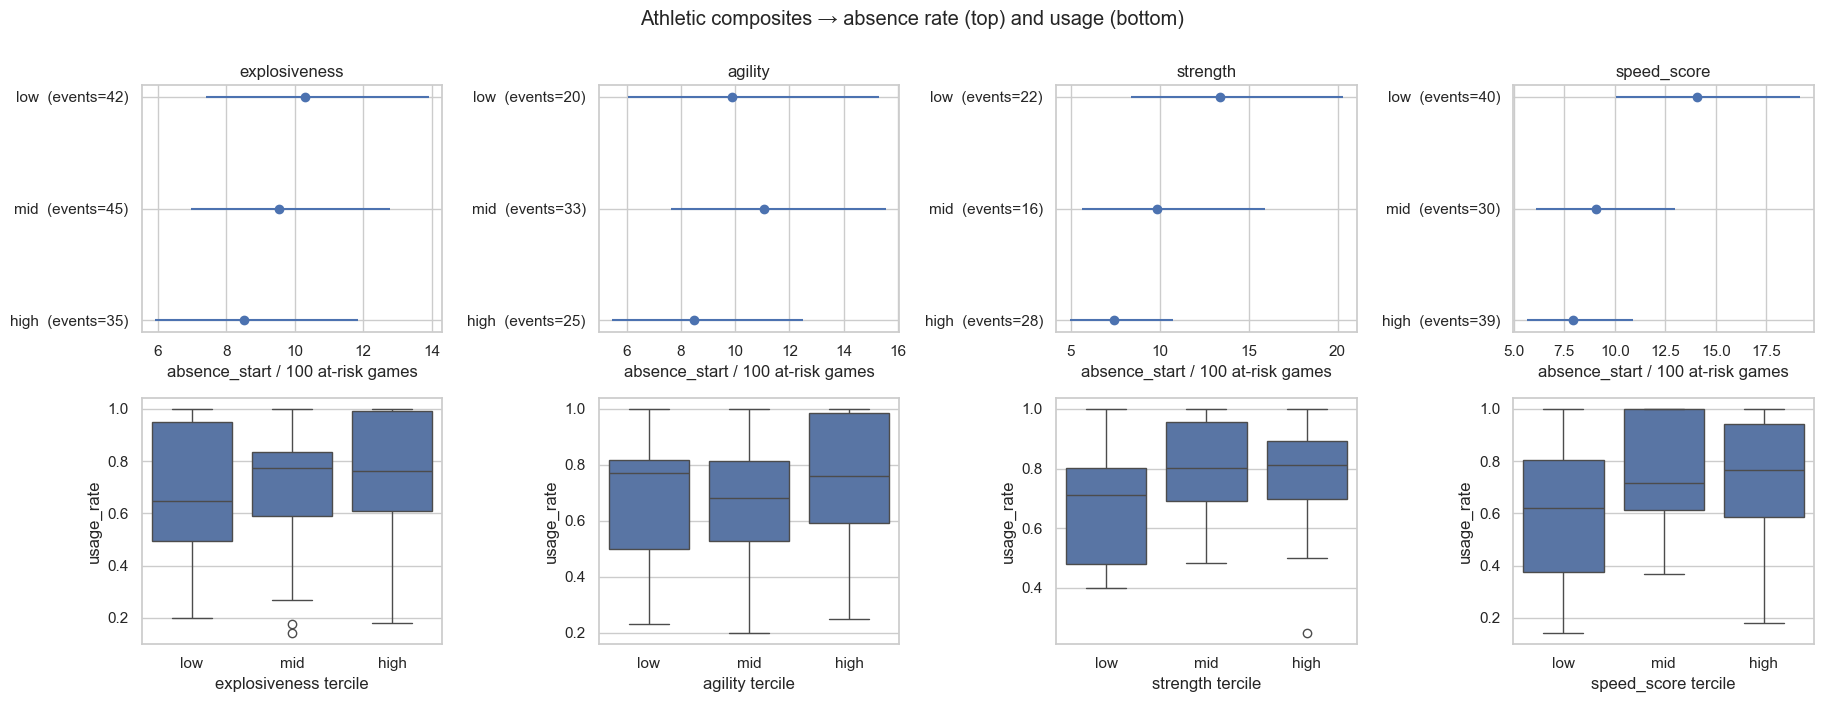

,metric,rate_low,rate_high,rate_ratio_high_vs_low,events,usage_spearman,usage_ci,n
0,explosiveness,10.29,8.52,0.828,122,0.069,"[-0.15, 0.30]",82
1,agility,9.90,8.47,0.856,78,0.154,"[-0.15, 0.42]",53
2,strength,13.41,7.43,0.554,66,-0.018,"[-0.36, 0.33]",39
3,speed_score,14.08,7.96,0.565,109,0.242,"[0.01, 0.45]",73
4,ten_yd_split,7.88,11.80,1.497,109,-0.187,"[-0.40, 0.05]",73
5,three_cone,10.09,10.06,0.997,59,-0.044,"[-0.35, 0.28]",43
6,broad_jump,7.74,6.33,0.818,114,-0.071,"[-0.31, 0.17]",75


In [8]:
def zpos(c, sign=1):
    return sign * (ol[c] - ol.groupby("pos_group")[c].transform("mean")) / ol.groupby("pos_group")[c].transform("std")

parts = {"explosiveness": [("broad_jump", 1), ("vertical", 1), ("ten_yd_split", -1)],
         "agility": [("three_cone", -1), ("short_shuttle", -1)],
         "strength": [("bench_reps", 1)]}
for name, comps in parts.items():
    zs = [zpos(c, s) for c, s in comps if c in ol]
    ol[name] = pd.concat(zs, axis=1).mean(axis=1, skipna=True) if zs else np.nan
    ol[f"{name}_n_tests"] = pd.concat([ol[c].notna() for c, _ in comps if c in ol], axis=1).sum(axis=1) if zs else 0
if "forty" in ol and W: ol["speed_score"] = ol[W] * 200 / ol["forty"] ** 4
ATH = [c for c in ["explosiveness", "agility", "strength", "speed_score", "ten_yd_split", "three_cone", "broad_jump"] if c in ol]
res_ath = tercile_view(ATH, title="Athletic composites → absence rate (top) and usage (bottom)")
res_ath

## 6. Angle 3: Opt-outs as a signal

Prospects skip Combine drills for strategic reasons or because they're hurt. If players who skipped more drills go on to miss more NFL games, the opt-out pattern itself is a cheap, pre-draft risk feature. It also tells you whether imputing missing drills would bias a model.

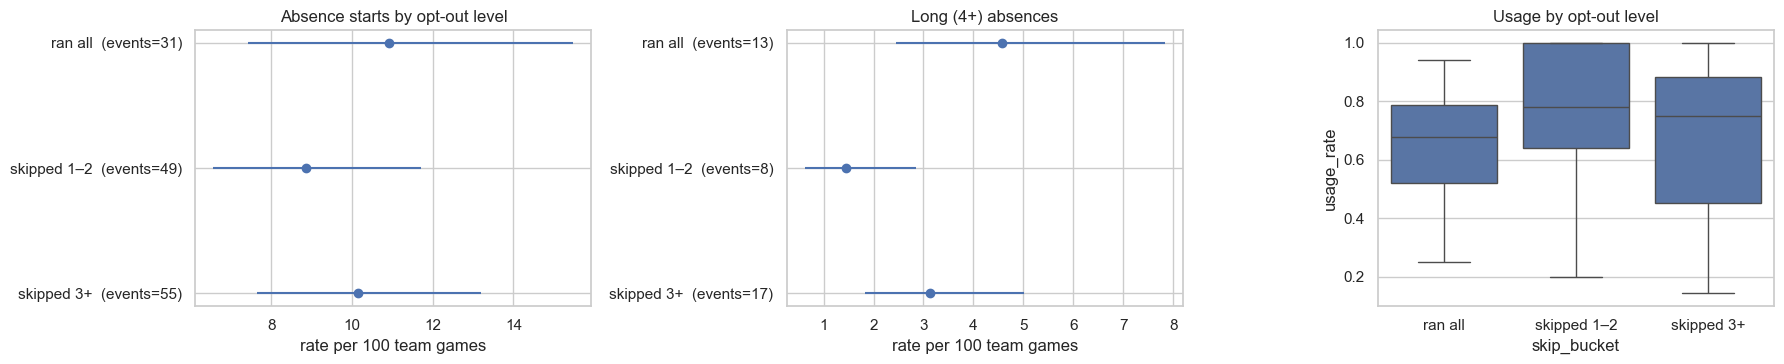

absence                                        long                                  
            players events exposure   rate ci_lo  ci_hi players events exposure  rate ci_lo ci_hi
skip_bucket                                                                                      
ran all          16     31      284  10.92  7.42  15.49      16     13      284  4.58  2.44  7.83
skipped 1–2      38     49      553   8.86  6.56  11.71      38      8      553  1.45  0.62  2.85
skipped 3+       37     55      542  10.15  7.64  13.21      37     17      542  3.14  1.83  5.02

,ran it,skipped it
absence starts per 100 at-risk games,,
forty,9.87,9.45
ten_yd_split,9.87,9.45
vertical,9.13,14.37
broad_jump,9.17,15.44
three_cone,10.05,9.60
short_shuttle,9.93,9.65
bench_reps,9.38,10.22


In [9]:
TESTS = [c for c in ["forty", "ten_yd_split", "vertical", "broad_jump", "three_cone", "short_shuttle", "bench_reps"] if c in ol]
ol["n_skipped"] = ol[TESTS].isna().sum(axis=1)
ol["skip_bucket"] = pd.cut(ol["n_skipped"], [-1, 0, 2, len(TESTS)], labels=["ran all", "skipped 1–2", "skipped 3+"])
pan = panel.merge(ol[["nfl_id", "skip_bucket"]], on="nfl_id")
fig, axes = plt.subplots(1, 3, figsize=(18, 3.8))
t1 = rate_table(pan, "skip_bucket", "absence_start", "at_risk"); plot_rates(t1, "Absence starts by opt-out level", ax=axes[0])
t2 = rate_table(pan, "skip_bucket", "long_absence_start", "at_risk"); plot_rates(t2, f"Long ({LONG_ABSENCE}+) absences", ax=axes[1])
sns.boxplot(data=ol[ol["in_panel"]], x="skip_bucket", y="usage_rate", ax=axes[2]); axes[2].set_title("Usage by opt-out level")
plt.tight_layout(); plt.show()
display(pd.concat({"absence": t1, "long": t2}, axis=1))
skipped_each = {c: rate_table(pan.assign(sk=pan["nfl_id"].map(ol.set_index("nfl_id")[c].isna())), "sk", "absence_start", "at_risk")["rate"].to_dict()
                for c in TESTS}
display(pd.DataFrame(skipped_each).T.rename(columns={False: "ran it", True: "skipped it"}).round(2)
          .rename_axis("absence starts per 100 at-risk games"))

## 7. Angle 4: Combine movement quality from sensor tracking

Combine tracking adds things a stopwatch can't see. These features are computed per player from his lateral, back-and-forth drills (mirror or kick-slide type: any drill with direction reversals):
- **Peak braking**: the hardest deceleration along the drill axis (yd/s²).
- **Peak lateral speed**: the fastest movement along the main axis.
- **Directional asymmetry**: |peak speed one way − peak speed the other way| ÷ mean. Side-to-side asymmetry is a common injury-screening idea in sports medicine. The drill axis has no fixed left/right, so this measures the *size* of the asymmetry, not which side is weaker.
- **Reversal time**: how long it takes to go from max speed one way to moving the other way.

Attempts with lateral reversals, by drill:


,attempts
drill_name,
PASS_PRO_MIRROR_DRILL,121
FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE,120
SCREEN_DRILL,117
OL_PULL_DRILL_FOLD_BLOCK_RIGHT,84
SHORT_SHUTTLE,70
OL_PULL_DRILL_LONG_PULL_RIGHT,63
THREE_CONE_DRILL,54
OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT,44
PASS_RUSH_DROP,12


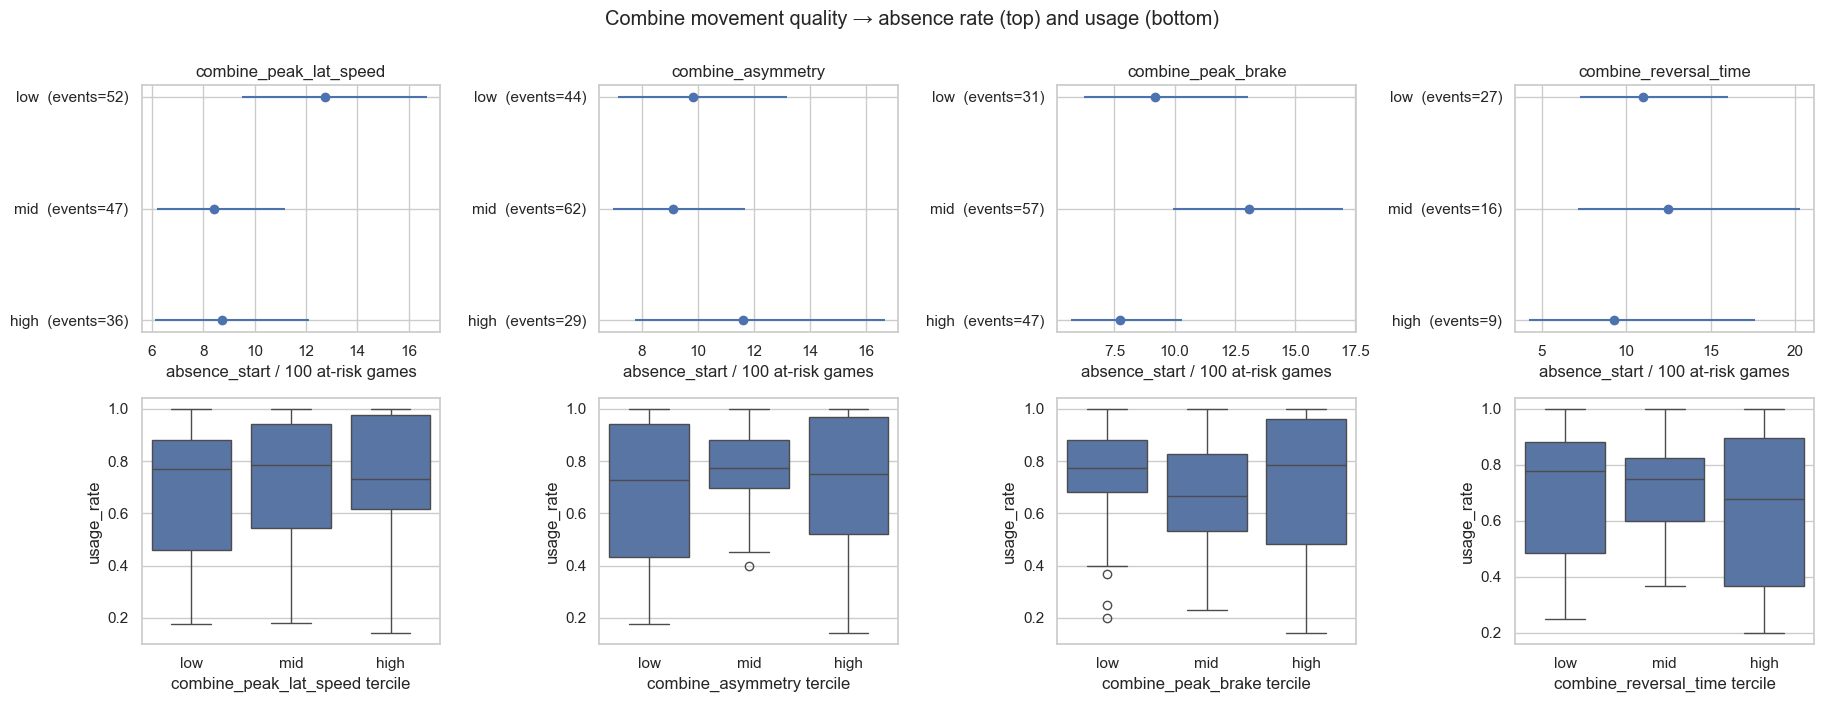

,metric,rate_low,rate_high,rate_ratio_high_vs_low,events,usage_spearman,usage_ci,n
0,combine_peak_lat_speed,12.75,8.74,0.685,135,-0.062,"[-0.26, 0.15]",91
1,combine_asymmetry,9.82,11.60,1.181,135,0.032,"[-0.19, 0.26]",91
2,combine_peak_brake,9.20,7.74,0.841,135,-0.032,"[-0.27, 0.20]",91
3,combine_reversal_time,11.02,9.28,0.842,52,0.008,"[-0.34, 0.40]",33


In [10]:
DRILL_FIXES = {"PASS_PRO-MIRROR_DRILL": "PASS_PRO_MIRROR_DRILL", "LINE": "LINE_DRILL"}
ct = pd.read_csv(find_csv("combine_tracking"), na_values=NULLS)
if "entity_type" in ct: ct = ct[ct["entity_type"] == "PLAYER"]
ct = ct[ct["nfl_id"].isin(ol["nfl_id"])].copy()
ct["drill_name"] = ct["drill_name"].replace(DRILL_FIXES)
ct["time"] = pd.to_datetime(ct["time"], errors="coerce")
ct = ct.sort_values(["event_id", "nfl_id", "time"])

def lateral_quality(r):
    t = (r["time"] - r["time"].iloc[0]).dt.total_seconds().to_numpy()
    if len(t) < 8 or np.any(np.diff(t) <= 0): return None
    xy = np.c_[r["x"].to_numpy(float), r["y"].to_numpy(float)]
    xy -= xy.mean(axis=0)
    axis = np.linalg.svd(xy, full_matrices=False)[2][0]
    pos = xy @ axis
    v = np.gradient(pos, t)
    acc = np.gradient(v, t)
    vs = v[np.abs(v) > 0.3]
    if len(vs) < 4 or (np.diff(np.sign(vs)) != 0).sum() < 1: return None   # needs at least one reversal
    pos_pk, neg_pk = v.max(), -v.min()
    brake = np.nanmax(-acc * np.sign(v))   # deceleration opposite to current motion
    i_pk = np.argmax(np.abs(v)); after = np.flatnonzero(np.sign(v[i_pk:]) != np.sign(v[i_pk]))
    return {"peak_lat_speed": max(pos_pk, neg_pk), "asymmetry": abs(pos_pk - neg_pk) / ((pos_pk + neg_pk) / 2),
            "peak_brake": brake, "reversal_time": t[i_pk + after[0]] - t[i_pk] if len(after) else np.nan}

rows = []
for (ev, nid, dn), r in ct.groupby(["event_id", "nfl_id", "drill_name"], sort=False):
    q = lateral_quality(r)
    if q: rows.append({"nfl_id": nid, "drill_name": dn, **q})
latq = pd.DataFrame(rows)
print("Attempts with lateral reversals, by drill:"); display(latq["drill_name"].value_counts().to_frame("attempts"))

# Player-level: mean over attempts in lateral drills (z within drill first, so drills are comparable)
LQ = ["peak_lat_speed", "asymmetry", "peak_brake", "reversal_time"]
for c in LQ: latq[c + "_z"] = latq.groupby("drill_name")[c].transform(lambda s: (s - s.mean()) / s.std())
pq = latq.groupby("nfl_id")[[c + "_z" for c in LQ]].mean().rename(columns=lambda c: "combine_" + c.replace("_z", ""))
ol = ol.drop(columns=[c for c in pq if c in ol]).merge(pq, left_on="nfl_id", right_index=True, how="left")
MQ = list(pq.columns)
res_mq = tercile_view(MQ, title="Combine movement quality → absence rate (top) and usage (bottom)")
res_mq

## 8. Angle 5: In-game workload and the acute:chronic ratio

This is the most direct "load" angle. For each player-game, the tracking gives:
- **snaps**
- **post-snap distance**: yards traveled in the first `LOAD_WINDOW_S` s of each rep, summed over the game
- **high-intensity frames**: frames with acceleration or deceleration ≥ `HI_ACCEL` yd/s², which captures explosive starts and braking

Then, following the workload literature, the **acute:chronic ratio (ACWR)** = this game's load ÷ his mean load over the previous 4 games (at least 3 required). The question is whether load spikes precede an absence starting **the next game**.

Game-only load misses practice load, which teams track with GPS and this dataset doesn't. Treat this as a partial measure.

In [11]:
KEEP = ["game_id", "play_id", "nfl_id", "time", "x", "y", "s", "a", "event"]
SNAP = {"ball_snap", "snap_direct", "autoevent_ballsnap"}
if TRK_CACHE.exists():
    trk = pd.read_parquet(TRK_CACHE)
    print("loaded cache:", TRK_CACHE)
else:
    ids = set(ol["nfl_id"]); parts = []
    for season in SEASONS:
        f = find_csv(f"game_tracking_{season}")
        cols = [c for c in KEEP if c in pd.read_csv(f, nrows=1).columns]
        for ch in pd.read_csv(f, usecols=cols, chunksize=2_000_000, na_values=NULLS):
            parts.append(ch[ch["nfl_id"].isin(ids)])
        print(season, "scanned")
    trk = pd.concat(parts, ignore_index=True)
    trk.to_parquet(TRK_CACHE, index=False)
trk = trk[[c for c in KEEP if c in trk]].copy()
trk["time"] = pd.to_datetime(trk["time"], errors="coerce")
trk = trk.sort_values(["game_id", "play_id", "nfl_id", "time"])

k = ["game_id", "play_id", "nfl_id"]
snap_t = trk.loc[trk["event"].isin(SNAP)].groupby(k)["time"].min().rename("snap_time")
trk = trk.merge(snap_t, left_on=k, right_index=True, how="inner")
trk["t"] = (trk["time"] - trk["snap_time"]).dt.total_seconds()
w = trk[(trk["t"] >= 0) & (trk["t"] <= LOAD_WINDOW_S)].copy()
g = w.groupby(k)
w["step"] = np.hypot(g["x"].diff(), g["y"].diff()).fillna(0)
w["dv"] = g["s"].diff() / g["t"].diff()
w["hi"] = (w["a"] >= HI_ACCEL) if "a" in w else (w["dv"].abs() >= HI_ACCEL)
w["hi_decel"] = w["dv"] <= -HI_ACCEL
rep_load = w.groupby(k).agg(dist=("step", "sum"), hi_frames=("hi", "sum"), hi_decel=("hi_decel", "sum"), peak_s=("s", "max"))
game_load = rep_load.groupby(["game_id", "nfl_id"]).agg(trk_reps=("dist", "size"), dist=("dist", "sum"),
                                                        hi_frames=("hi_frames", "sum"), hi_decel=("hi_decel", "sum"),
                                                        dist_per_rep=("dist", "mean"), peak_s=("peak_s", "max")).reset_index()
panel = panel.drop(columns=[c for c in game_load if c in panel and c not in ["game_id", "nfl_id"]]).merge(game_load, on=["game_id", "nfl_id"], how="left")
cov = panel.loc[panel["played"], "trk_reps"].notna().mean()
print(f"Played games with tracking load: {cov:.0%}")
display(panel.loc[panel["played"], ["snaps", "trk_reps", "dist", "dist_per_rep", "hi_frames", "hi_decel"]].describe().round(2))

loaded cache: ol_tracking_cache.parquet
Played games with tracking load: 95%


,snaps,trk_reps,dist,dist_per_rep,hi_frames,hi_decel
count,1644.00,1554.00,1554.00,1554.00,1554.00,1554.00
mean,52.67,55.17,426.75,7.62,41.13,49.17
std,23.21,20.95,167.12,1.26,34.19,27.40
min,1.00,1.00,0.29,0.23,0.00,0.00
25%,48.00,52.00,386.29,7.15,14.00,31.00
50%,60.00,61.00,469.17,7.70,34.00,48.50
75%,68.00,68.00,531.59,8.27,60.00,66.00
max,96.00,96.00,846.74,15.16,240.00,158.00


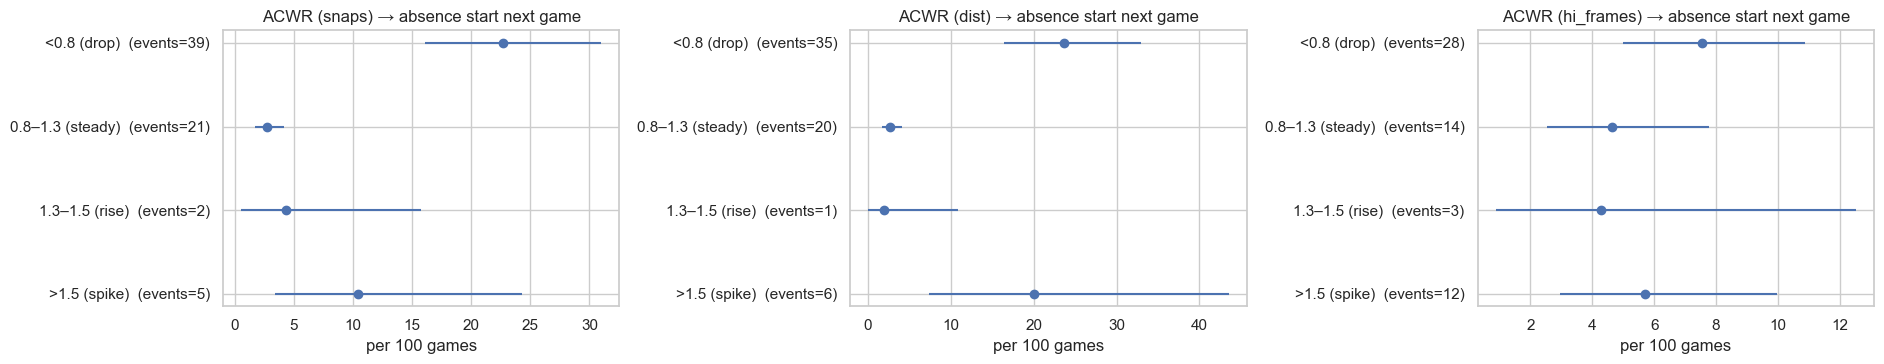

snaps                                         dist                                      hi_frames                                   
                 players events exposure   rate  ci_lo  ci_hi players events exposure   rate  ci_lo  ci_hi   players events exposure  rate ci_lo  ci_hi
band                                                                                                                                                   
<0.8 (drop)           58     39      172  22.67  16.12  31.00      53     35      148  23.65  16.47  32.89        60     28      372  7.53  5.00  10.88
0.8–1.3 (steady)      63     21      764   2.75   1.70   4.20      63     20      745   2.68   1.64   4.15        54     14      302  4.64  2.53   7.78
1.3–1.5 (rise)        34      2       46   4.35   0.53  15.71      37      1       51   1.96   0.05  10.92        35      3       70  4.29  0.88  12.52
>1.5 (spike)          29      5       48  10.42   3.38  24.31      22      6       30  20.00   7.34  43.53        58     12      210  5.71  2.95   9.98

In [12]:
# ACWR per metric: this game ÷ mean of previous 4 played games (≥3 required). Outcome: absence starts NEXT game.
panel = panel.sort_values(["nfl_id", "season", "team", "team_game_no"])
gg = panel.groupby(["nfl_id", "season", "team"])
panel["next_absence_start"] = gg["absence_start"].shift(-1, fill_value=False)
panel["next_at_risk"] = panel["played"] & panel["established"]
for m in ["snaps", "dist", "hi_frames"]:
    v = panel[m].where(panel["played"])
    chronic = v.groupby([panel["nfl_id"], panel["season"], panel["team"]]).transform(lambda s: s.shift().rolling(4, min_periods=3).mean())
    panel[f"acwr_{m}"] = v / chronic
    panel[f"cum_{m}"] = gg[m].cumsum()

BANDS = [0, 0.8, 1.3, 1.5, np.inf]; BL = ["<0.8 (drop)", "0.8–1.3 (steady)", "1.3–1.5 (rise)", ">1.5 (spike)"]
fig, axes = plt.subplots(1, 3, figsize=(19, 3.8))
acwr_tabs = {}
for ax, m in zip(axes, ["snaps", "dist", "hi_frames"]):
    d = panel[panel["next_at_risk"] & panel[f"acwr_{m}"].notna()].copy()
    d["band"] = pd.cut(d[f"acwr_{m}"], BANDS, labels=BL)
    t = rate_table(d, "band", "next_absence_start", "next_at_risk"); acwr_tabs[m] = t
    plot_rates(t, f"ACWR ({m}) → absence start next game", ax=ax, xlabel="per 100 games")
plt.tight_layout(); plt.show()
display(pd.concat(acwr_tabs, axis=1))

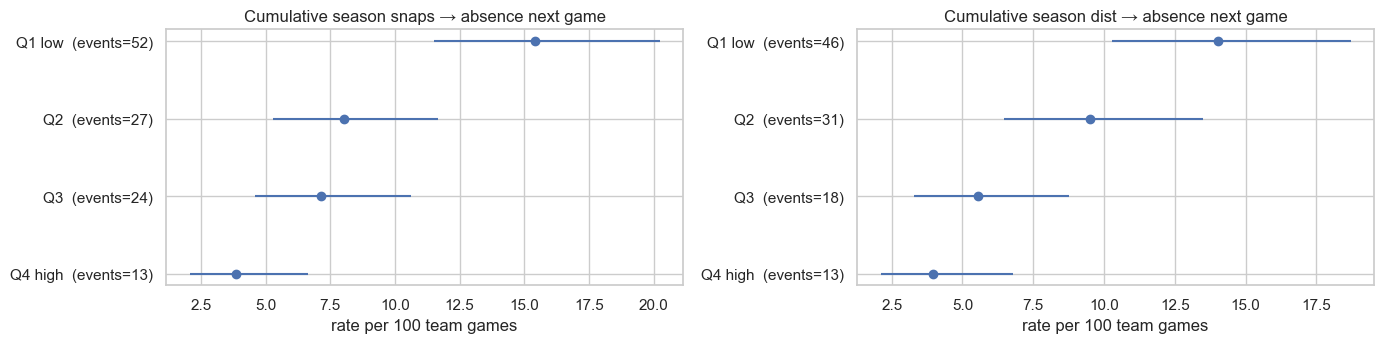

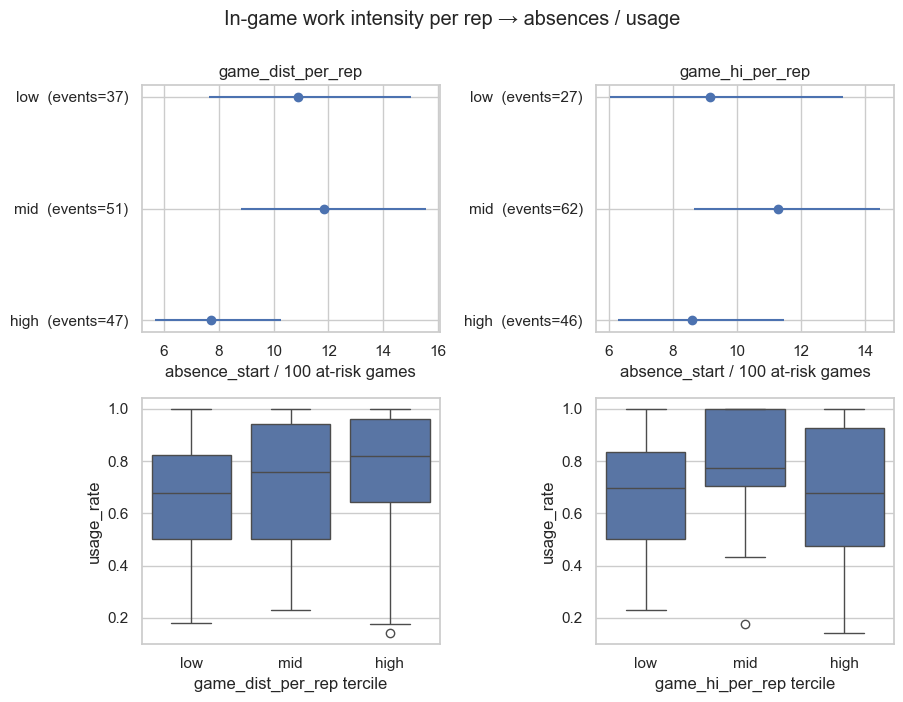

,metric,rate_low,rate_high,rate_ratio_high_vs_low,events,usage_spearman,usage_ci,n
0,game_dist_per_rep,10.88,7.73,0.71,135,0.228,"[0.01, 0.43]",89
1,game_hi_per_rep,9.15,8.60,0.94,135,-0.032,"[-0.24, 0.19]",89


In [13]:
# Cumulative season load: do absences cluster after heavy accumulated workloads?
d = panel[panel["next_at_risk"]].copy()
for m in ["snaps", "dist"]:
    d[f"cum_{m}_q"] = d.groupby("season")[f"cum_{m}"].transform(lambda s: pd.qcut(s, 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"], duplicates="drop"))
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
for ax, m in zip(axes, ["snaps", "dist"]):
    if d[f"cum_{m}_q"].notna().any():
        plot_rates(rate_table(d.dropna(subset=[f"cum_{m}_q"]), f"cum_{m}_q", "next_absence_start", "next_at_risk"),
                   f"Cumulative season {m} → absence next game", ax=ax)
plt.tight_layout(); plt.show()

# Per-rep intensity profile vs. absences (player level): who works "hotter" per rep?
pl = panel[panel["played"]].groupby("nfl_id").agg(dist_per_rep=("dist_per_rep", "mean"),
                                                  hi_per_rep=("hi_frames", lambda s: s.sum()),
                                                  reps=("trk_reps", "sum"))
pl["hi_per_rep"] = pl["hi_per_rep"] / pl["reps"]
ol = ol.drop(columns=[c for c in ["game_dist_per_rep", "game_hi_per_rep"] if c in ol]).merge(
    pl[["dist_per_rep", "hi_per_rep"]].rename(columns=lambda c: "game_" + c), left_on="nfl_id", right_index=True, how="left")
res_game = tercile_view(["game_dist_per_rep", "game_hi_per_rep"], title="In-game work intensity per rep → absences / usage")
res_game

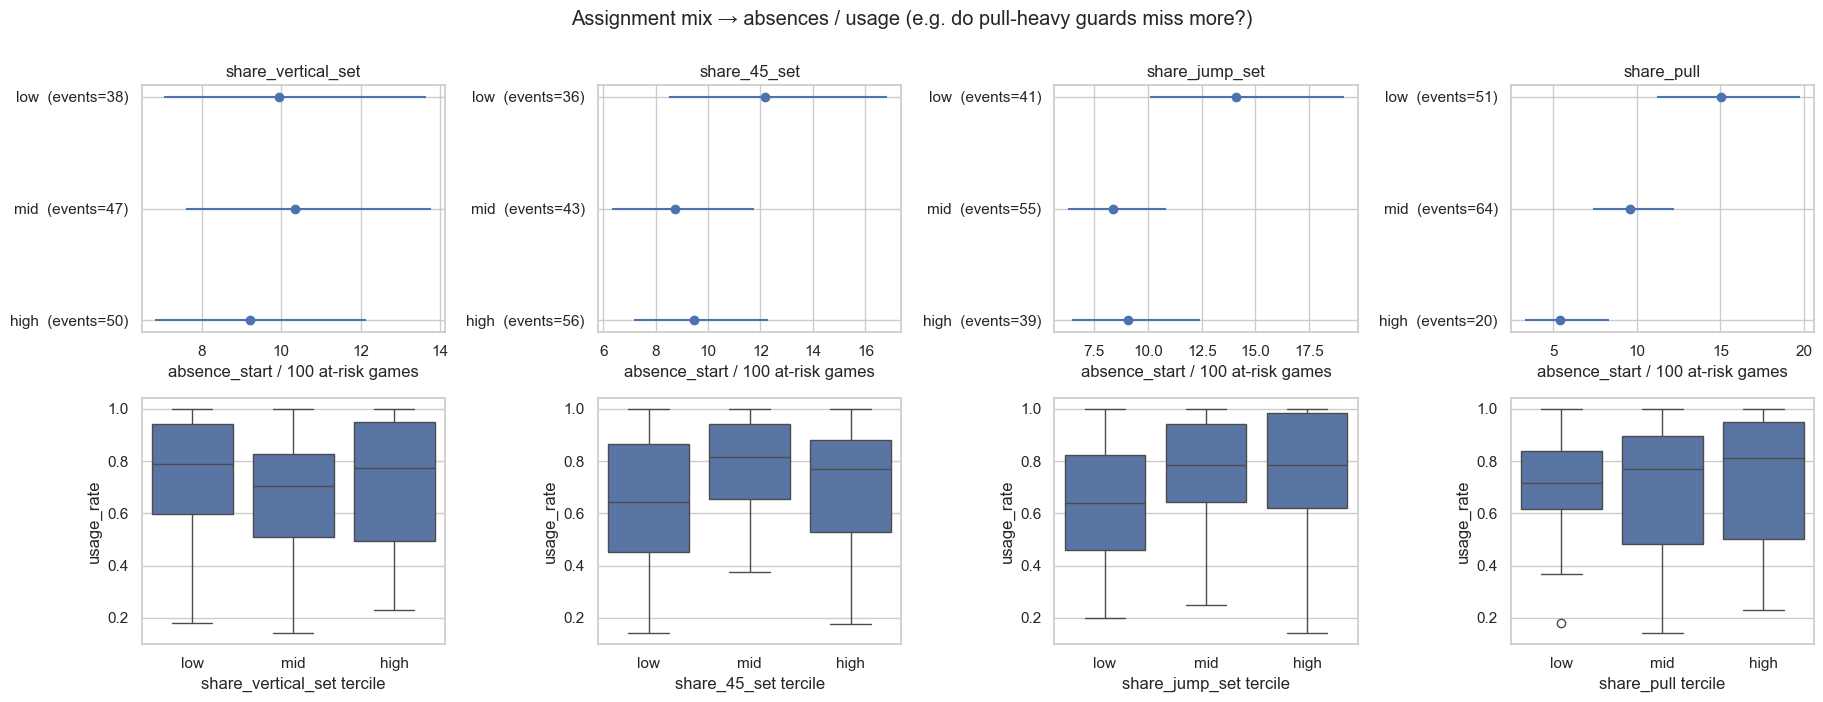

,metric,rate_low,rate_high,rate_ratio_high_vs_low,events,usage_spearman,usage_ci,n
0,share_vertical_set,9.95,9.21,0.926,135,0.027,"[-0.20, 0.24]",91
1,share_45_set,12.16,9.48,0.780,135,0.035,"[-0.20, 0.25]",91
2,share_jump_set,14.09,9.09,0.645,135,0.168,"[-0.06, 0.38]",91
3,share_pull,15.04,5.39,0.358,135,-0.007,"[-0.22, 0.20]",91
4,share_climb,15.09,8.79,0.583,135,0.290,"[0.08, 0.47]",91
5,share_zone_reach,11.38,5.88,0.517,135,0.101,"[-0.12, 0.31]",91
6,share_slide,11.08,11.41,1.030,135,0.048,"[-0.15, 0.27]",91


In [14]:
# Optional: play-type mix from the movement-classes notebook (if its output exists)
mv = Path("ol_rep_movement_classes.csv")
if mv.exists():
    mvc = pd.read_csv(mv)
    mix = pd.crosstab(mvc["nfl_id"], mvc["rule_class"], normalize="index")
    keep_cols = [c for c in ["vertical_set", "45_set", "jump_set", "pull", "climb", "zone_reach", "slide"] if c in mix]
    mix = mix[keep_cols].add_prefix("share_")
    ol = ol.drop(columns=[c for c in mix if c in ol]).merge(mix, left_on="nfl_id", right_index=True, how="left")
    res_mix = tercile_view(list(mix.columns), title="Assignment mix → absences / usage (e.g. do pull-heavy guards miss more?)")
    display(res_mix)
else:
    print("Run the movement-classes notebook first to add assignment-mix features (ol_rep_movement_classes.csv).")

## 9. Angle 6: Game context

These are per-game exposure factors. They describe when absences start, so they're more useful as covariates in a game-level hazard model than as player traits. The literature is mixed on short rest. Surface effects are better established for lower-extremity injuries, but only apply if `games.csv` has a surface field.

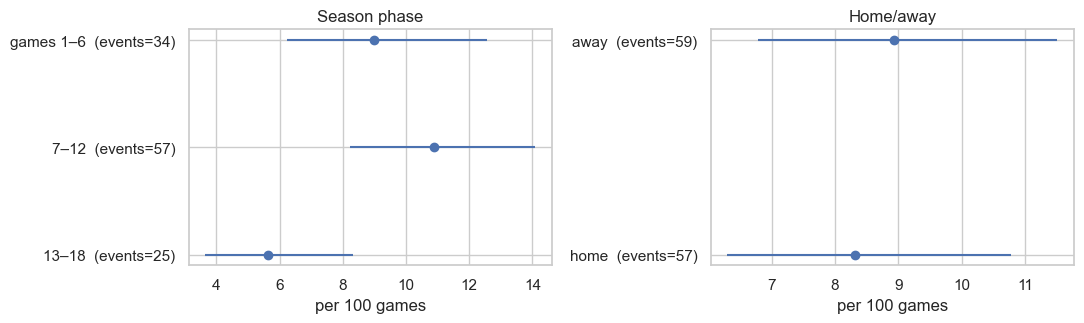

In [15]:
d = panel[panel["next_at_risk"]].copy()
nxt = panel.groupby(["nfl_id", "season", "team"])
d["next_rest"] = nxt["rest_days"].shift(-1).reindex(d.index)
d["rest_band"] = pd.cut(d["next_rest"], [0, 5, 8, 30], labels=["short (≤5d)", "regular (6–8d)", "long/bye (9d+)"])
d["season_phase"] = pd.cut(d["team_game_no"], [0, 6, 12, 18], labels=["games 1–6", "7–12", "13–18"])
plots = [("season_phase", "Season phase")] + ([("rest_band", "Rest before next game")] if d["next_rest"].notna().any() else [])
if SURF:
    d["surface"] = d[SURF].astype(str).str.lower().map(lambda s: "turf" if any(k in s for k in ["turf", "artificial", "synthetic", "a_turf", "field"]) else ("grass" if "grass" in s else s))
    plots.append(("surface", "Surface (game played)"))
d["home_away"] = np.where(d["home"] == 1, "home", "away"); plots.append(("home_away", "Home/away"))
fig, axes = plt.subplots(1, len(plots), figsize=(5.5 * len(plots), 3.4), squeeze=False)
for ax, (c, ttl) in zip(axes.flat, plots):
    dd = d.dropna(subset=[c])
    if len(dd): plot_rates(rate_table(dd, c, "next_absence_start", "next_at_risk"), ttl, ax=ax, xlabel="per 100 games")
plt.tight_layout(); plt.show()

## 10. Angle 7: What drives usage? Talent vs. durability

Usage is easier to model than injury because it's observed every game. It mixes three things, though: talent (draft capital), body type and durability. This section shows how much of usage the pre-draft features track, and whether body or athletic signals survive after **removing what draft capital already explains**. The residual is computed by regressing usage on log(pick), which is still descriptive.

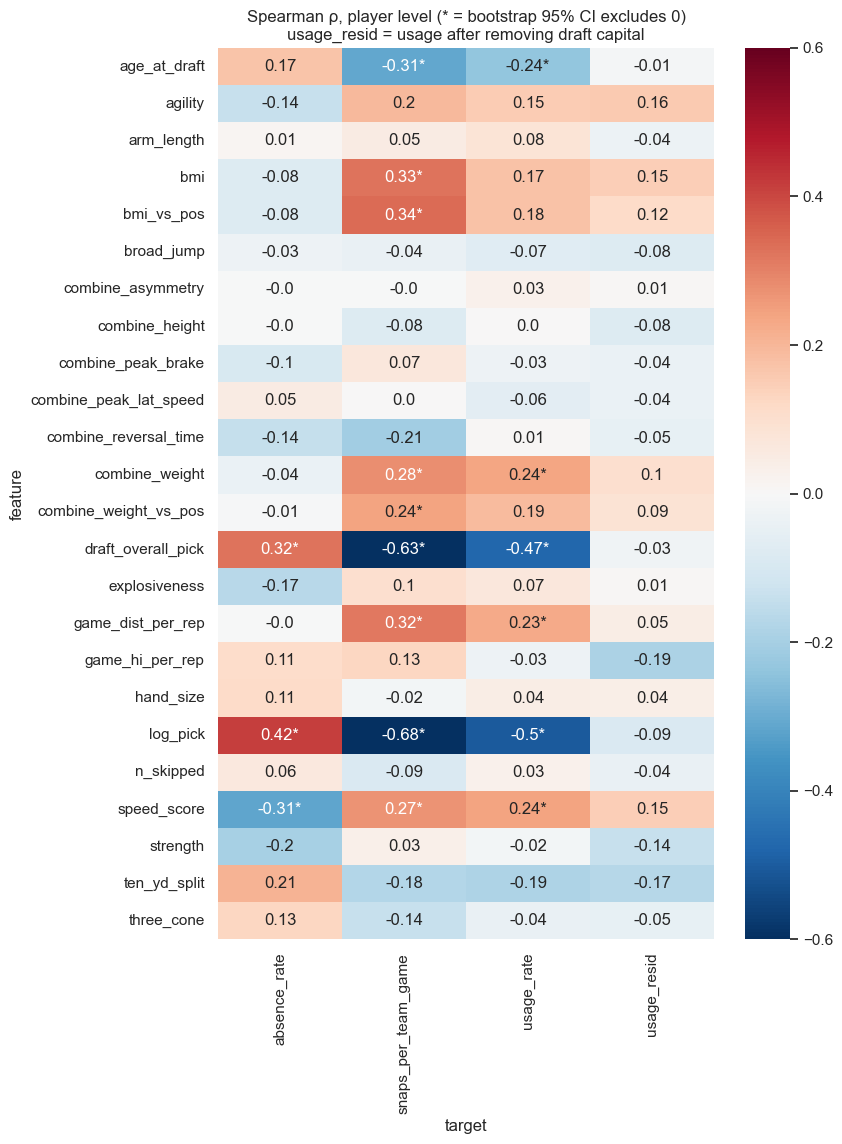

In [16]:
u = ol[ol["in_panel"]].copy()
if PICK and u[PICK].notna().sum() > 10:
    u["log_pick"] = np.log(u[PICK].fillna(u[PICK].max() + 32))   # UDFA → after last pick
    b = np.polyfit(u["log_pick"], u["usage_rate"], 1)
    u["usage_resid"] = u["usage_rate"] - np.polyval(b, u["log_pick"])
else:
    u["usage_resid"] = u["usage_rate"]
FEATS = [c for c in ([PICK, "log_pick", "age_at_draft"] + BODY + ATH + MQ + ["n_skipped", "game_dist_per_rep", "game_hi_per_rep"])
         if c and c in u and u[c].notna().sum() >= 10]
rows = []
for c in dict.fromkeys(FEATS):
    for target in ["usage_rate", "usage_resid", "snaps_per_team_game", "absence_starts"]:
        y = u[target] / u["at_risk"].replace(0, np.nan) * 100 if target == "absence_starts" else u[target]
        r, lo, hi, n = boot_spearman(u[c], y)
        rows.append({"feature": c, "target": target if target != "absence_starts" else "absence_rate", "rho": r, "ci_lo": lo, "ci_hi": hi, "n": n})
corr = pd.DataFrame(rows)
heat = corr.pivot(index="feature", columns="target", values="rho")
sig = corr.assign(s=(corr["ci_lo"] > 0) | (corr["ci_hi"] < 0)).pivot(index="feature", columns="target", values="s")
plt.figure(figsize=(8, 0.42 * len(heat) + 1.5))
sns.heatmap(heat, annot=heat.round(2).astype(str) + np.where(sig.fillna(False), "*", ""), fmt="", cmap="RdBu_r", center=0, vmin=-.6, vmax=.6)
plt.title("Spearman ρ, player level (* = bootstrap 95% CI excludes 0)\nusage_resid = usage after removing draft capital"); plt.show()

In [19]:
def partial_spearman(x, y, z, n=N_BOOT):
    # Spearman correlation of x and y with z held constant (rank-residual method), plus bootstrap CI
    d = pd.DataFrame({"x": x, "y": y, "z": z}).dropna().rank()
    if len(d) < 15: return np.nan, np.nan, np.nan, len(d)
    def pc(df):
        rx = df["x"] - np.polyval(np.polyfit(df["z"], df["x"], 1), df["z"])
        ry = df["y"] - np.polyval(np.polyfit(df["z"], df["y"], 1), df["z"])
        return np.corrcoef(rx, ry)[0, 1]
    r = pc(d)
    bs = [pc(d.iloc[RNG.integers(0, len(d), len(d))]) for _ in range(n)]
    return r, *np.nanpercentile(bs, [2.5, 97.5]), len(d)

u = ol[ol["in_panel"]].copy()
u["log_pick"] = np.log(u[PICK].fillna(u[PICK].max() + 32))
u["absence_rate"] = u["absence_starts"] / u["at_risk"].replace(0, np.nan) * 100
u["long_absence_rate"] = u["long_absences"] / u["at_risk"].replace(0, np.nan) * 100

feats = ["speed_score", "ten_yd_split", "strength", "combine_weight", "bmi_vs_pos", "agility",
         "explosiveness", "combine_peak_lat_speed", "combine_asymmetry", "game_dist_per_rep", "age_at_draft"]
rows = []
for f in [f for f in feats if f in u]:
    for tgt in ["usage_rate", "absence_rate", "long_absence_rate"]:
        r_raw = stats.spearmanr(u[f], u[tgt], nan_policy="omit")[0]
        r, lo, hi, n = partial_spearman(u[f], u[tgt], u["log_pick"])
        rows.append({"feature": f, "target": tgt, "raw_rho": r_raw, "partial_rho": r, "ci_lo": lo, "ci_hi": hi, "n": n})
pc = pd.DataFrame(rows)
pc["survives"] = (pc["ci_lo"] > 0) | (pc["ci_hi"] < 0)
pc.pivot(index="feature", columns="target", values=["raw_rho", "partial_rho"]).round(2)

raw_rho                               partial_rho                             
target                 absence_rate long_absence_rate usage_rate absence_rate long_absence_rate usage_rate
feature                                                                                                   
age_at_draft                   0.17              0.09      -0.24        -0.03             -0.05       0.02
agility                       -0.14             -0.04       0.15        -0.13             -0.03       0.09
bmi_vs_pos                    -0.08             -0.11       0.18        -0.03             -0.08       0.04
combine_asymmetry             -0.00             -0.09       0.03         0.07             -0.05      -0.05
combine_peak_lat_speed         0.05              0.07      -0.06         0.11              0.11      -0.10
combine_weight                -0.04             -0.01       0.24         0.11              0.09       0.06
explosiveness                 -0.17             -0.06       0.07        -0.10             -0.02      -0.02
game_dist_per_rep             -0.00              0.01       0.23         0.13              0.10       0.06
speed_score                   -0.31             -0.23       0.24        -0.18             -0.13       0.06
strength                      -0.20              0.10      -0.02        -0.15              0.13      -0.08
ten_yd_split                   0.21              0.16      -0.19         0.14              0.12      -0.11

## 11. Synthesis: which angles have signal, and what model each supports

In [17]:
summary_rows = []
def add(df, angle, outcome="absence rate"):
    if df is None or len(df) == 0: return
    for _, r in df.iterrows():
        summary_rows.append({"angle": angle, "feature": r["metric"], "outcome": outcome,
                             "high_vs_low_rate_ratio": r.get("rate_ratio_high_vs_low"), "events": r.get("events"),
                             "usage_rho": r.get("usage_spearman"), "usage_ci": r.get("usage_ci")})
add(res_body, "1 body"); add(res_ath, "2 athleticism"); add(res_mq, "4 combine movement"); add(res_game, "5 in-game intensity")
syn = pd.DataFrame(summary_rows)
syn["|log RR|"] = np.log(syn["high_vs_low_rate_ratio"].astype(float)).abs()
display(syn.sort_values("|log RR|", ascending=False).round(3))

for m, t in acwr_tabs.items():
    if {"0.8–1.3 (steady)", ">1.5 (spike)"} <= set(t.index.astype(str)):
        base, spike = t.loc["0.8–1.3 (steady)", "rate"], t.loc[">1.5 (spike)", "rate"]
        print(f"ACWR {m}: spike vs steady rate ratio = {spike / base:.2f}" if base > 0 else f"ACWR {m}: no events in steady band")
print(f"\nEvent counts available: absence starts={int(panel['absence_start'].sum())}, "
      f"long absences={int(panel['long_absence_start'].sum())}, exit→miss={int(panel['exit_then_miss'].sum())}")

,angle,feature,outcome,high_vs_low_rate_ratio,events,usage_rho,usage_ci,|log RR|
9,2 athleticism,strength,absence rate,0.554,66,-0.018,"[-0.36, 0.33]",0.591
10,2 athleticism,speed_score,absence rate,0.565,109,0.242,"[0.01, 0.45]",0.571
11,2 athleticism,ten_yd_split,absence rate,1.497,109,-0.187,"[-0.40, 0.05]",0.403
14,4 combine movement,combine_peak_lat_speed,absence rate,0.685,135,-0.062,"[-0.26, 0.15]",0.378
4,1 body,bmi_vs_pos,absence rate,0.700,135,0.177,"[-0.03, 0.36]",0.357
18,5 in-game intensity,game_dist_per_rep,absence rate,0.710,135,0.228,"[0.01, 0.43]",0.342
1,1 body,combine_weight,absence rate,0.726,135,0.237,"[0.05, 0.40]",0.320
13,2 athleticism,broad_jump,absence rate,0.818,114,-0.071,"[-0.31, 0.17]",0.201
7,2 athleticism,explosiveness,absence rate,0.828,122,0.069,"[-0.15, 0.30]",0.189
6,1 body,hand_size,absence rate,1.202,135,0.042,"[-0.15, 0.23]",0.184


ACWR snaps: spike vs steady rate ratio = 3.79
ACWR dist: spike vs steady rate ratio = 7.46
ACWR hi_frames: spike vs steady rate ratio = 1.23

Event counts available: absence starts=135, long absences=38, exit→miss=52


### Modeling paths these angles support

| Target | Unit | Inputs | Model family | Why |
|---|---|---|---|---|
| **Usage rate** (games played ÷ team games) | player-season | body, athletic composites, opt-outs, draft capital, prior-season usage | beta regression / fractional logit, partial pooling by position | bounded 0–1, observed for everyone with NFL games |
| **Absence episodes** | player | pre-draft features (Angles 1–4), exposure offset = at-risk games | negative binomial / Poisson with offset | counts with unequal follow-up across draft classes |
| **Time to first long absence** | player | pre-draft features | Cox or discrete-time survival | handles right-censoring (2025 class has 1 season) |
| **Absence next game** | player-game | ACWR, cumulative load, rest, surface, season phase, plus player traits | discrete-time hazard (logistic on the panel), player random effect | uses every game, separates in-season load from fixed traits |
| **Exit → miss** | player-game | same as above | rare-event logistic (penalized), or merge with absence starts | cleanest injury proxy but the fewest events |

### How to read this notebook honestly
- **Count the events before believing a rate ratio.** The synthesis table prints them. With a few dozen events per position, only large effects (RR ≈ 2+) are detectable.
- **Draft capital confounds usage.** Use `usage_resid` (Section 10) to judge whether a body or athletic signal adds anything beyond what teams already priced in.
- **Absence ≠ injury.** The next step that would most improve every angle here is joining public injury reports to the panel. That would turn the proxies into labels, or at least validate them.
- **Pre-specify** the definitions (`REGULAR_SNAPS`, `LONG_ABSENCE`, ACWR window) before modeling. Tuning them while looking at these plots builds the noise into the model.

In [18]:
ol.to_csv("ol_injury_usage_player_level.csv", index=False)
panel.to_csv("ol_injury_usage_player_game_panel.csv", index=False)
print("Saved ol_injury_usage_player_level.csv and ol_injury_usage_player_game_panel.csv")

Saved ol_injury_usage_player_level.csv and ol_injury_usage_player_game_panel.csv
